# Final Section 6 prediction model — code cleanup only

This notebook reproduces Section 6 of `OnlyPredictionModel_Copy.ipynb`.
The original training target, ordered inputs, data filtering, 80/20 split,
Random Forest fallback settings, external SOM preprocessing and mass reconstruction
are preserved. No model improvements or feature corrections are applied.

The original Section 2 removal of **Mean Setback Height** is retained as a
dependency. The original `"volume"` substring filter is unchanged: it excludes
Surface-to-Volume Ratio, Volumetric Convexity and Volumetric Symmetry Score.
Height and the full-dataset Slenderness Ratio remain unchanged.

The original source ran through Section 6 without runtime corrections. Only the
malformed internal results table is replaced with correctly labelled display
tables calculated from the same predictions. Baseline comparisons are recorded
separately in `OnlyPredictionModel_Audit`; this notebook requires no audit files.

## 1. Load and prepare the original SR7 / SR11 / SR15 data

In [1]:
import csv
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------
# SECTION 1A - CLEAN DATASETS
# ---------------------------------------------------



labels_path = Path(
    r"C:\Users\lilli\OneDrive\Desktop\Master Thesis\Grasshopper Data\MidJune\Labels.csv"
)

resultsSR7_folder = Path(
    r"C:\Users\lilli\OneDrive\Desktop\Master Thesis\Grasshopper Data\MidJune\SR7\results"
)

resultsSR11_folder = Path(
    r"C:\Users\lilli\OneDrive\Desktop\Master Thesis\Grasshopper Data\MidJune\SR11\results"
)

resultsSR15_folder = Path(
    r"C:\Users\lilli\OneDrive\Desktop\Master Thesis\Grasshopper Data\MidJune\SR15\results"
)









SAVE_OUTPUTS = False


with labels_path.open(newline="", encoding="utf-8-sig") as labels_file:
    labels = next(csv.reader(labels_file))

expected_value_count = len(labels)

duplicate_column_names = sorted([
    column
    for column, count in Counter(labels).items()
    if count > 1
])


def make_unique_columns(columns):
    seen = Counter()
    unique_columns = []

    for column in columns:
        seen[column] += 1
        if seen[column] == 1:
            unique_columns.append(column)
        else:
            unique_columns.append(f"{column}__{seen[column]}")

    return unique_columns


unique_labels = make_unique_columns(labels)


def load_single_sr_dataset(sr_label, results_folder):
    csv_files = sorted(results_folder.glob("*.csv"))
    rows = []
    failed_files = []

    for file in csv_files:
        try:
            result_data = pd.read_csv(file, header=None, encoding="cp1252")
        except Exception as exc:
            failed_files.append({
                "file": file.name,
                "expected": expected_value_count,
                "actual": f"read error: {exc}",
            })
            continue

        actual_value_count = result_data.shape[1] if len(result_data) == 1 else result_data.size

        if actual_value_count != expected_value_count:
            failed_files.append({
                "file": file.name,
                "expected": expected_value_count,
                "actual": actual_value_count,
            })
            continue

        row = result_data.iloc[0].tolist()
        row.append(file.stem)
        rows.append(row)

    df = pd.DataFrame(
        rows,
        columns=unique_labels + ["Building ID"]
    )

    df["SR Dataset"] = sr_label

    text_columns = [
        "Building Name",
        "Building ID",
        "Interstory Drift Limit",
        "Analysis Info",
        "SR Dataset",
    ]

    numeric_columns = [
        column
        for column in df.columns
        if column not in text_columns
    ]

    for column in numeric_columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

    if "Plan Aspect Ratio" in df.columns:
        df["Plan Aspect Ratio"] = (
            pd.to_numeric(df["Plan Aspect Ratio"], errors="coerce")
            .replace(0, np.nan)
            .rdiv(1.0)
        )

    df = df[
        df["Structural Mass"].notna()
        & (df["Structural Mass"] > 0)
    ].copy()


    if "Metric Volume" not in df.columns and "Volume" in df.columns:
        df["Metric Volume"] = df["Volume"]

    if "Setback Count" not in df.columns and "Number of Setbacks" in df.columns:
        df["Setback Count"] = df["Number of Setbacks"]

    diagnostics = {
        "files_found": len(csv_files),
        "files_loaded": len(rows),
        "failed_files": failed_files,
        "shape": df.shape,
    }

    return df, diagnostics


sr7dataset, sr7_diagnostics = load_single_sr_dataset(
    "SR7",
    resultsSR7_folder,
)

sr11dataset, sr11_diagnostics = load_single_sr_dataset(
    "SR11",
    resultsSR11_folder,
)

sr15dataset, sr15_diagnostics = load_single_sr_dataset(
    "SR15",
    resultsSR15_folder,
)

fulldataset = pd.concat(
    [sr7dataset, sr11dataset, sr15dataset],
    ignore_index=True
)

if "Metric Volume" not in fulldataset.columns and "Volume" in fulldataset.columns:
    fulldataset["Metric Volume"] = fulldataset["Volume"]

if "Setback Count" not in fulldataset.columns and "Number of Setbacks" in fulldataset.columns:
    fulldataset["Setback Count"] = fulldataset["Number of Setbacks"]


print("Loaded source rows:", len(fulldataset))

Loaded source rows: 4095


## 2. Analysis dataset and retained feature dependencies

In [2]:
geometry_metrics = [
    "Slenderness Ratio",
    "Plan Aspect Ratio",
    "Volumetric Convexity",
    "Surface-to-Volume Ratio",
    "Mean Compactness",
    "Volumetric Symmetry Score",
    "Plan Aspect Ratio Variation",
    "Max CoM",
    "Bulge Factor",
    "Bulge Height Index",
    "Top-to-Base Width Ratio",
    "Max-to-Min Width Ratio",
    "Mean Floor Area Decrease (%)",
    "Mean Floor Area Increase (%)",
    "Number of Setbacks",
    "Mean Setback Magnitude",
    "Mean Setback Height",
    "Weighted Mean Setback Height",
    "Mean Inward Taper (%)",
    "Mean Outward Taper (%)",
    "Taper Sign Change",
    "Facade Verticality Ratio",
]

performance_metrics = [
    "Structural Mass",
    "Max Base Shear",
    "Max Overturning Moment",
    "Max Interstory Drift Ratio",
]

analysis_dataset_metadata = {}

analysis_fulldataset_with_metadata = fulldataset.copy()

def create_analysis_dataset(
    cleaned_dataset,
    dataset_label,
    hold_slenderness_constant
):
    analysis_source_df = cleaned_dataset.copy()

    twist_mask = pd.Series(False, index=analysis_source_df.index)
    for twist_column in ["Building Name", "Building ID"]:
        if twist_column in analysis_source_df.columns:
            twist_mask = twist_mask | analysis_source_df[twist_column].astype(str).str.contains(
                "twist",
                case=False,
                na=False
            )

    removed_twist_buildings = int(twist_mask.sum())
    analysis_source_df = analysis_source_df.loc[~twist_mask].copy()

    selected_geometry_metrics = [
        col for col in geometry_metrics
        if col in analysis_source_df.columns
    ]
    selected_performance_metrics = [
        col for col in performance_metrics
        if col in analysis_source_df.columns
    ]

    common_slenderness_value = np.nan
    # Original ALL call uses hold_slenderness_constant=False.

    analysis_identifier_columns = [
        column for column in [
            "Building ID",
            "Building Name",
            "Variant",
            "Height",
            "Surface Area",
            "SR Dataset"
        ]
        if column in analysis_source_df.columns
    ]

    analysis_columns = (
        analysis_identifier_columns +
        selected_geometry_metrics +
        selected_performance_metrics
    )
    analysis_dataset = analysis_source_df[analysis_columns].copy()

    analysis_dataset_metadata[dataset_label] = {
        "removed_twist_buildings": removed_twist_buildings,
        "geometry_metrics": selected_geometry_metrics,
        "performance_metrics": selected_performance_metrics,
        "common_slenderness_value": common_slenderness_value,
        "surface_area_included": "Surface Area" in analysis_dataset.columns,
    }

    return analysis_dataset

analysis_fulldataset = create_analysis_dataset(
    fulldataset,
    "ALL",
    hold_slenderness_constant=False
)

### Dependency moved from Section 2A.1

The correlation figures are removed. Their subsequent explicit exclusion of Mean Setback Height is preserved, because Section 6 receives this modified feature list.

In [3]:
redundant_geometry_metrics = [
    "Mean Setback Height"
]

geometry_metrics = [
    metric for metric in geometry_metrics
    if metric not in redundant_geometry_metrics
]

for dataset_label in analysis_dataset_metadata:
    analysis_dataset_metadata[dataset_label]["geometry_metrics"] = [
        metric
        for metric in analysis_dataset_metadata[dataset_label]["geometry_metrics"]
        if metric not in redundant_geometry_metrics
    ]

analysis_fulldataset = analysis_fulldataset.drop(
    columns=[metric for metric in redundant_geometry_metrics if metric in analysis_fulldataset.columns],
    errors="ignore"
)

geometry_metrics = analysis_dataset_metadata["ALL"]["geometry_metrics"]

### Dependency moved from Section 4A

Only imports and the original feature-list construction remain. Section 4 model training and its separate training-row filter are not dependencies of Section 6.

In [4]:
from IPython.display import display

# ---------------------------------------------------
# SECTION 4A
# DATA PREPARATION
# ---------------------------------------------------

import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

section4_df = analysis_fulldataset.copy()

section4_targets = [
    "Structural Mass",
    "Max Base Shear",
    "Max Overturning Moment"
]

if "analysis_dataset_metadata" in globals() and "ALL" in analysis_dataset_metadata:
    section4_geometry_metrics = analysis_dataset_metadata["ALL"].get(
        "geometry_metrics",
        geometry_metrics
    )
else:
    section4_geometry_metrics = geometry_metrics

section4_geometry_metrics = [
    metric
    for metric in section4_geometry_metrics
    if metric in section4_df.columns
]

section4_feature_columns = section4_geometry_metrics.copy()

section4_feature_columns = [
    column
    for column in section4_feature_columns
    if (
        column in section4_df.columns
        and column not in section4_targets
        and column not in ["Metric Volume", "Volume", "Metric Height"]
        and not str(column).lower().startswith("height-corrected")
    )
]

## 3. External SOM buildings — original preprocessing

In [5]:
# ---------------------------------------------------
# SECTION 4D
# EXTERNAL TEST BUILDINGS
# ---------------------------------------------------

external_test_folder = Path(
    r"C:\Users\lilli\OneDrive\Desktop\Master Thesis\Grasshopper Data\MidJune\SOM"
)

external_labels = [
    "Building Name",
    "Height",
    "Volume",
    "Structural Mass",
    "Displacement Limit",
    "Max Displacement",
    "Displacement WYP",
    "Displacement WYN",
    "Displacement WXP",
    "Displacement WXN",
    "Displacement G",
    "Max DEnergy",
    "DEnergy WYP",
    "DEnergy WYN",
    "DEnergy WXP",
    "DEnergy WXN",
    "DEnergy G",
    "Max Base Shear",
    "Max Overturning Moment",
    "Max Interstory Drift Ratio",
    "Interstory Drift Limit",
    "Average Thickness",
    "Metric Height",
    "Metric Volume",
    "Slenderness Ratio",
    "Plan Aspect Ratio",
    "Volumetric Convexity",
    "Surface-to-Volume Ratio",
    "Mean Compactness",
    "Volumetric Symmetry Score",
    "Plan Aspect Ratio Variation",
    "Max CoM",
    "Bulge Factor",
    "Bulge Height Index",
    "Top-to-Base Width Ratio",
    "Max-to-Min Width Ratio",
    "Mean Floor Area Decrease (%)",
    "Mean Floor Area Increase (%)",
    "Number of Setbacks",
    "Mean Setback Magnitude",
    "Mean Setback Height",
    "Weighted Mean Setback Height",
    "Mean Inward Taper (%)",
    "Mean Outward Taper (%)",
    "Taper Sign Change",
    "Twist Ratio",
    "Facade Verticality Ratio",
    "Analysis Info",
]

external_test_rows = []
external_test_building_ids = []

for file in sorted(external_test_folder.glob("*.csv")):
    row = pd.read_csv(
        file,
        header=None,
        encoding="cp1252"
    ).iloc[0].tolist()

    if len(row) != len(external_labels):
        raise ValueError(
            f"{file.name}: expected {len(external_labels)} values using external labels, "
            f"but got {len(row)} values."
        )

    external_test_rows.append(row)
    external_test_building_ids.append(file.stem)

external_test_df = pd.DataFrame(
    external_test_rows,
    columns=external_labels
)
external_test_df["Building ID"] = external_test_building_ids
external_test_df["Variant"] = np.nan

if "Setback Count" not in external_test_df.columns and "Number of Setbacks" in external_test_df.columns:
    external_test_df["Setback Count"] = external_test_df["Number of Setbacks"]

external_text_columns = [
    "Building Name",
    "Building ID",
    "Interstory Drift Limit",
    "Analysis Info",
    "Variant",
]

for column in external_test_df.columns:
    if column not in external_text_columns:
        external_test_df[column] = pd.to_numeric(
            external_test_df[column],
            errors="coerce"
        )

if "Plan Aspect Ratio" in external_test_df.columns:
    external_test_df["Plan Aspect Ratio"] = (
        pd.to_numeric(external_test_df["Plan Aspect Ratio"], errors="coerce")
        .replace(0, np.nan)
        .rdiv(1.0)
    )

if "Setback Count" in external_test_df.columns:
    external_non_setback_mask = (
        pd.to_numeric(
            external_test_df["Setback Count"],
            errors="coerce"
        ).fillna(0)
        == 0
    )
    for setback_height_column in ["Mean Setback Height", "Weighted Mean Setback Height"]:
        if setback_height_column in external_test_df.columns:
            external_test_df.loc[
                external_non_setback_mask
                & external_test_df[setback_height_column].isna(),
                setback_height_column
            ] = 1.0

print("External SOM buildings:", external_test_df["Building ID"].tolist())

External SOM buildings: ['BurjKhalifa', 'Hancock', 'JinMao', 'Sears']


## 6. Original final prediction model

The original names and calculation code are retained to make equivalence review straightforward. The direct output is Structural Mass / Metric Volume. The earlier `random_forest_settings` dictionary is not read by Section 6: its own fallback is preserved verbatim.

Exact Section 6 feature order:
1. Height
2. Slenderness Ratio
3. Plan Aspect Ratio
4. Mean Compactness
5. Plan Aspect Ratio Variation
6. Max CoM
7. Bulge Factor
8. Bulge Height Index
9. Top-to-Base Width Ratio
10. Max-to-Min Width Ratio
11. Mean Floor Area Decrease (%)
12. Mean Floor Area Increase (%)
13. Number of Setbacks
14. Mean Setback Magnitude
15. Weighted Mean Setback Height
16. Mean Inward Taper (%)
17. Mean Outward Taper (%)
18. Taper Sign Change
19. Facade Verticality Ratio
Source rows: 4095
Eligible rows: 1965
Fitted/train rows: 1572
Held-out/test rows: 393
Exact Section 6 Random Forest settings:
{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 500, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_s

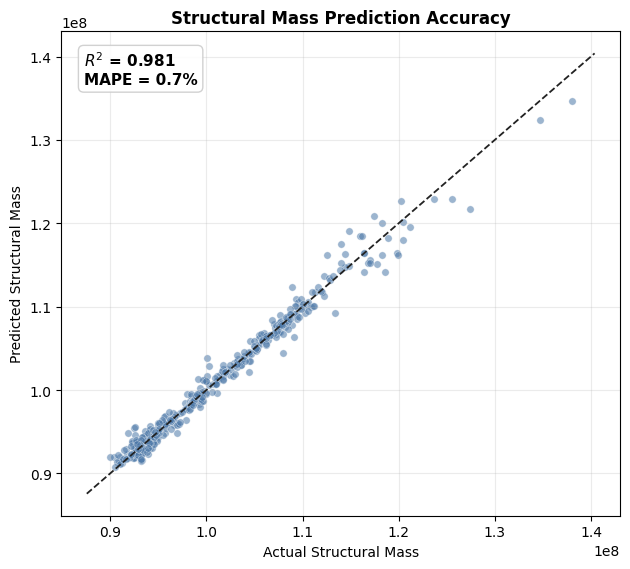

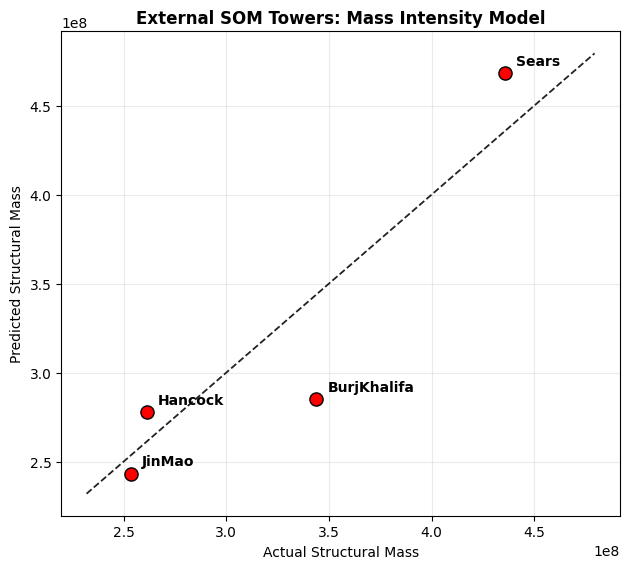

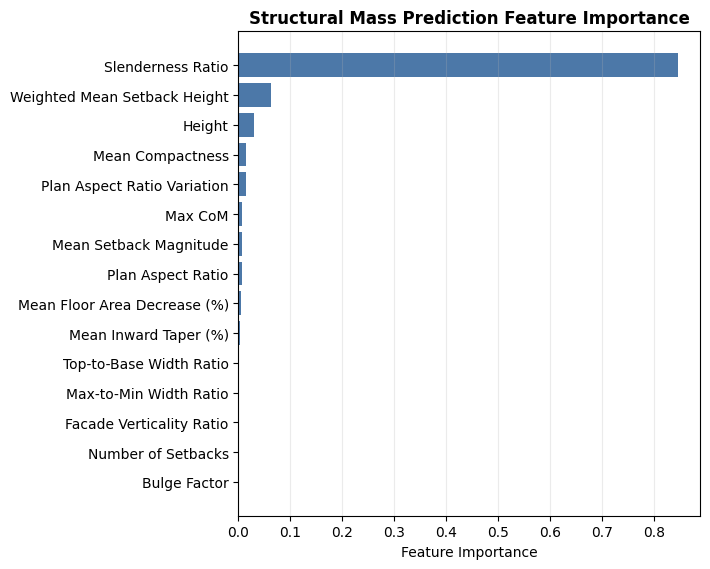

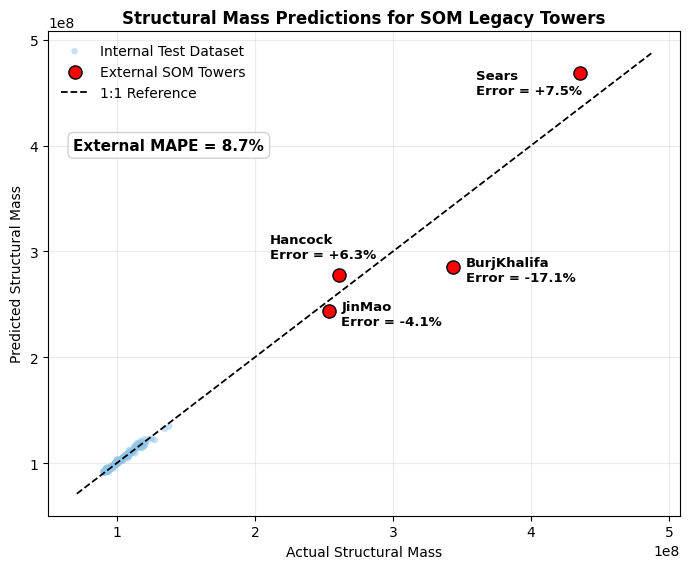

In [6]:
# ---------------------------------------------------
# SECTION 6
# MASS INTENSITY PREDICTION MODEL
# ---------------------------------------------------

section6_source_df = analysis_fulldataset.copy()

if "Height" not in section6_source_df.columns:
    if "Metric Height" in section6_source_df.columns:
        section6_source_df["Height"] = section6_source_df["Metric Height"]
    elif "analysis_fulldataset_with_metadata" in globals() and "Height" in analysis_fulldataset_with_metadata.columns:
        section6_source_df["Height"] = analysis_fulldataset_with_metadata.loc[
            section6_source_df.index,
            "Height"
        ]
    elif "analysis_fulldataset_with_metadata" in globals() and "Metric Height" in analysis_fulldataset_with_metadata.columns:
        section6_source_df["Height"] = analysis_fulldataset_with_metadata.loc[
            section6_source_df.index,
            "Metric Height"
        ]
    else:
        raise KeyError("Section 6 requires Height, but no Height or Metric Height column is available.")

if "Metric Volume" not in section6_source_df.columns:
    if "analysis_fulldataset_with_metadata" in globals() and "Metric Volume" in analysis_fulldataset_with_metadata.columns:
        section6_source_df["Metric Volume"] = analysis_fulldataset_with_metadata.loc[
            section6_source_df.index,
            "Metric Volume"
        ]
    elif "Volume" in section6_source_df.columns:
        section6_source_df["Metric Volume"] = section6_source_df["Volume"]
    elif "analysis_fulldataset_with_metadata" in globals() and "Volume" in analysis_fulldataset_with_metadata.columns:
        section6_source_df["Metric Volume"] = analysis_fulldataset_with_metadata.loc[
            section6_source_df.index,
            "Volume"
        ]
    else:
        raise KeyError("Section 6 requires Metric Volume, but no Metric Volume or Volume column is available.")

if "Structural Mass" not in section6_source_df.columns:
    if "analysis_fulldataset_with_metadata" in globals() and "Structural Mass" in analysis_fulldataset_with_metadata.columns:
        section6_source_df["Structural Mass"] = analysis_fulldataset_with_metadata.loc[
            section6_source_df.index,
            "Structural Mass"
        ]
    else:
        raise KeyError("Section 6 requires Structural Mass, but it is not available.")

section6_excluded_feature_columns = [
    "Metric Height",
    "Structural Mass",
    "Max Base Shear",
    "Max Overturning Moment",
    "Height-corrected Structural Mass",
    "Height-corrected Max Base Shear",
    "Height-corrected Max Overturning Moment",
    "Metric Volume",
    "Volume",
    "Building Volume",
    "Total Volume",
]

section6_base_feature_columns = (
    section4_feature_columns.copy()
    if "section4_feature_columns" in globals()
    else geometry_metrics.copy()
)

section6_feature_columns = [
    column
    for column in section6_base_feature_columns
    if (
        column in section6_source_df.columns
        and column not in section6_excluded_feature_columns
        and not str(column).lower().startswith("height-corrected")
        and "volume" not in str(column).lower()
    )
]

if "Height" not in section6_feature_columns:
    section6_feature_columns = ["Height", *section6_feature_columns]

print("Exact Section 6 feature order:")
for feature_index, feature_name in enumerate(section6_feature_columns, start=1):
    print(f"{feature_index}. {feature_name}")

section6_required_columns = [
    "Structural Mass",
    "Metric Volume",
    *section6_feature_columns
]

section6_training_df = section6_source_df[section6_required_columns].copy()
for column in section6_required_columns:
    section6_training_df[column] = pd.to_numeric(
        section6_training_df[column],
        errors="coerce"
    )

section6_training_df = section6_training_df.replace([np.inf, -np.inf], np.nan)
section6_training_df = section6_training_df[section6_training_df["Metric Volume"] > 0].copy()
section6_training_df["Structural Mass Intensity"] = (
    section6_training_df["Structural Mass"]
    / section6_training_df["Metric Volume"]
)
section6_training_df = (
    section6_training_df
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=[*section6_required_columns, "Structural Mass Intensity"])
    .copy()
)

if section6_training_df.empty:
    raise ValueError("Section 6 training dataset is empty after dropping missing required values.")

section6_X = section6_training_df[section6_feature_columns].copy()
section6_y = section6_training_df["Structural Mass Intensity"].copy()
section6_random_state = globals().get("section4_random_state", 42)

(
    section6_X_train,
    section6_X_test,
    section6_y_train,
    section6_y_test,
    section6_train_index,
    section6_test_index
) = train_test_split(
    section6_X,
    section6_y,
    section6_training_df.index,
    test_size=0.2,
    random_state=section6_random_state
)

section6_model_settings = (
    section4_model_settings.copy()
    if "section4_model_settings" in globals()
    else {"n_estimators": 500, "random_state": section6_random_state}
)
section6_model_settings.setdefault("random_state", section6_random_state)

print("Source rows:", len(section6_source_df))
print("Eligible rows:", len(section6_training_df))
print("Fitted/train rows:", len(section6_X_train))
print("Held-out/test rows:", len(section6_X_test))

section6_model = RandomForestRegressor(**section6_model_settings)
section6_model.fit(section6_X_train, section6_y_train)
print("Exact Section 6 Random Forest settings:")
print(section6_model.get_params())

section6_internal_predicted_intensity = section6_model.predict(section6_X_test)
section6_internal_actual_mass = section6_training_df.loc[
    section6_test_index,
    "Structural Mass"
]
section6_internal_actual_volume = section6_training_df.loc[
    section6_test_index,
    "Metric Volume"
]
section6_internal_actual_intensity = section6_training_df.loc[
    section6_test_index,
    "Structural Mass Intensity"
]
section6_internal_predicted_mass = (
    section6_internal_predicted_intensity
    * section6_internal_actual_volume.to_numpy(dtype=float)
)
section6_internal_error = (
    section6_internal_predicted_mass
    - section6_internal_actual_mass.to_numpy(dtype=float)
)

section6_internal_results = pd.DataFrame({
    "Actual Structural Mass": section6_internal_actual_mass.to_numpy(dtype=float),
    "Actual Metric Volume": section6_internal_actual_volume.to_numpy(dtype=float),
    "Actual Structural Mass Intensity": section6_internal_actual_intensity.to_numpy(dtype=float),
    "Predicted Structural Mass Intensity": section6_internal_predicted_intensity,
    "Predicted Structural Mass": section6_internal_predicted_mass,
    "Error": section6_internal_error,
    "Absolute Error": np.abs(section6_internal_error),
    "Percent Error (%)": 100 * section6_internal_error / section6_internal_actual_mass.to_numpy(dtype=float)
}, index=section6_test_index)

# Display-only cleanup: summary is printed in the final validation table below.

section6_external_df = external_test_df.copy()

if "Height" not in section6_external_df.columns:
    if "Metric Height" in section6_external_df.columns:
        section6_external_df["Height"] = section6_external_df["Metric Height"]
    else:
        raise KeyError("Section 6 external prediction requires Height or Metric Height.")

if "Metric Volume" not in section6_external_df.columns:
    if "Volume" in section6_external_df.columns:
        section6_external_df["Metric Volume"] = section6_external_df["Volume"]
    else:
        raise KeyError("Section 6 external prediction requires Metric Volume or Volume.")

if (
    "Weighted Mean Setback Height" in section6_external_df.columns
    and "Setback Count" in section6_external_df.columns
):
    section6_external_df["Weighted Mean Setback Height"] = pd.to_numeric(
        section6_external_df["Weighted Mean Setback Height"],
        errors="coerce"
    )
    section6_non_setback_mask = (
        pd.to_numeric(
            section6_external_df["Setback Count"],
            errors="coerce"
        ).fillna(0)
        == 0
    )
    section6_external_df.loc[
        section6_non_setback_mask
        & section6_external_df["Weighted Mean Setback Height"].isna(),
        "Weighted Mean Setback Height"
    ] = 1.0

section6_external_required_columns = [
    "Height",
    "Metric Volume",
    *section6_feature_columns
]
section6_missing_external_columns = [
    column
    for column in section6_external_required_columns
    if column not in section6_external_df.columns
]

if section6_missing_external_columns:
    raise KeyError(f"Section 6 external prediction columns are missing: {section6_missing_external_columns}")

section6_external_has_actual_mass = "Structural Mass" in section6_external_df.columns
if section6_external_has_actual_mass:
    section6_external_required_columns = [
        *section6_external_required_columns,
        "Structural Mass"
    ]

for column in section6_external_required_columns:
    section6_external_df[column] = pd.to_numeric(
        section6_external_df[column],
        errors="coerce"
    )

section6_external_missing_values = (
    section6_external_df[["Metric Volume", *section6_feature_columns]]
    .replace([np.inf, -np.inf], np.nan)
    .isna()
    .sum()
)
section6_external_missing_values = section6_external_missing_values[
    section6_external_missing_values > 0
]
if not section6_external_missing_values.empty:
    raise ValueError(
        "Section 6 external prediction has missing required values: "
        f"{section6_external_missing_values.to_dict()}"
    )

section6_external_X = section6_external_df[section6_feature_columns].copy()
section6_external_predicted_intensity = section6_model.predict(section6_external_X)
section6_external_predicted_mass = (
    section6_external_predicted_intensity
    * section6_external_df["Metric Volume"].to_numpy(dtype=float)
)

section6_external_results = pd.DataFrame({
    "Building ID": section6_external_df["Building ID"].to_numpy(),
    "Height": section6_external_df["Height"].to_numpy(dtype=float),
    "Metric Volume": section6_external_df["Metric Volume"].to_numpy(dtype=float),
    "Actual Structural Mass": (
        section6_external_df["Structural Mass"].to_numpy(dtype=float)
        if section6_external_has_actual_mass
        else np.nan
    ),
    "Predicted Structural Mass Intensity": section6_external_predicted_intensity,
    "Predicted Structural Mass": section6_external_predicted_mass
})

if section6_external_has_actual_mass:
    section6_external_results["Error"] = (
        section6_external_results["Predicted Structural Mass"]
        - section6_external_results["Actual Structural Mass"]
    )
    section6_external_results["Absolute Error"] = section6_external_results["Error"].abs()
    section6_external_results["Percent Error (%)"] = (
        100
        * section6_external_results["Error"]
        / section6_external_results["Actual Structural Mass"]
    )
else:
    section6_external_results["Error"] = np.nan
    section6_external_results["Absolute Error"] = np.nan
    section6_external_results["Percent Error (%)"] = np.nan

section6_som_building_order = ["Hancock", "JinMao", "BurjKhalifa", "Sears"]

section6_external_validation_summary = pd.DataFrame(columns=[
    "Building",
    "Actual Structural Mass",
    "Predicted Structural Mass",
    "Error",
    "Absolute Error",
    "Percent Error (%)",
    "MAE",
    "RMSE",
    "MAPE (%)"
])

if section6_external_has_actual_mass:
    section6_external_summary_rows = []
    section6_external_results_by_building = section6_external_results.set_index("Building ID")
    for building in section6_som_building_order:
        row = section6_external_results_by_building.loc[building]
        section6_external_summary_rows.append({
            "Building": building,
            "Actual Structural Mass": round(row["Actual Structural Mass"]),
            "Predicted Structural Mass": round(row["Predicted Structural Mass"]),
            "Error": round(row["Error"]),
            "Absolute Error": round(row["Absolute Error"]),
            "Percent Error (%)": round(row["Percent Error (%)"], 1),
            "MAE": "",
            "RMSE": "",
            "MAPE (%)": ""
        })

    section6_external_som_results = section6_external_results_by_building.loc[
        section6_som_building_order
    ]
    section6_external_summary_rows.append({
        "Building": "External SOM Towers (Overall)",
        "Actual Structural Mass": "",
        "Predicted Structural Mass": "",
        "Error": "",
        "Absolute Error": "",
        "Percent Error (%)": "",
        "MAE": round(mean_absolute_error(
            section6_external_som_results["Actual Structural Mass"],
            section6_external_som_results["Predicted Structural Mass"]
        )),
        "RMSE": round(np.sqrt(mean_squared_error(
            section6_external_som_results["Actual Structural Mass"],
            section6_external_som_results["Predicted Structural Mass"]
        ))),
        "MAPE (%)": round(
            np.abs(
                section6_external_som_results["Percent Error (%)"]
            ).mean(),
            1
        )
    })

    section6_external_validation_summary = pd.DataFrame(
        section6_external_summary_rows,
        columns=section6_external_validation_summary.columns
    )


def section6_reference_limits(*arrays):
    values = np.concatenate([
        np.asarray(array, dtype=float).ravel()
        for array in arrays
    ])
    values = values[np.isfinite(values)]
    min_value = values.min()
    max_value = values.max()
    padding = (max_value - min_value) * 0.05
    if padding == 0:
        padding = max(abs(max_value) * 0.05, 1.0)
    return min_value - padding, max_value + padding

fig, ax = plt.subplots(figsize=(6.4, 5.8))
ax.scatter(
    section6_internal_results["Actual Structural Mass"],
    section6_internal_results["Predicted Structural Mass"],
    s=28,
    alpha=0.55,
    color="#4C78A8",
    edgecolor="white",
    linewidth=0.4
)

min_value, max_value = section6_reference_limits(
    section6_internal_results["Actual Structural Mass"],
    section6_internal_results["Predicted Structural Mass"]
)

ax.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="#222222",
    linestyle="--",
    linewidth=1.3
)

# Performance annotation
internal_r2 = r2_score(
    section6_internal_results["Actual Structural Mass"],
    section6_internal_results["Predicted Structural Mass"]
)
internal_mape = np.abs(section6_internal_results["Percent Error (%)"]).mean()

ax.text(
    0.04,
    0.96,
    f"$R^2$ = {internal_r2:.3f}\nMAPE = {internal_mape:.1f}%",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=11,
    fontweight="bold",
    bbox=dict(
        facecolor="white",
        edgecolor="#cccccc",
        boxstyle="round,pad=0.35",
        alpha=0.9
    )
)

ax.set_title("Structural Mass Prediction Accuracy", fontweight="bold")
ax.set_xlabel("Actual Structural Mass")
ax.set_ylabel("Predicted Structural Mass")
ax.grid(True, alpha=0.25)
fig.tight_layout()
plt.show()



if section6_external_has_actual_mass:
    fig, ax = plt.subplots(figsize=(6.4, 5.8))
    ax.scatter(
        section6_external_results["Actual Structural Mass"],
        section6_external_results["Predicted Structural Mass"],
        s=90,
        color="red",
        edgecolor="black",
        linewidth=1.0,
        zorder=10
    )
    for _, row in section6_external_results.iterrows():
        ax.annotate(
            row["Building ID"],
            (
                row["Actual Structural Mass"],
                row["Predicted Structural Mass"]
            ),
            xytext=(8, 6),
            textcoords="offset points",
            fontsize=10,
            fontweight="bold"
        )
    min_value, max_value = section6_reference_limits(
        section6_external_results["Actual Structural Mass"],
        section6_external_results["Predicted Structural Mass"]
    )
    ax.plot(
        [min_value, max_value],
        [min_value, max_value],
        color="#222222",
        linestyle="--",
        linewidth=1.3
    )
    ax.set_title("External SOM Towers: Mass Intensity Model", fontweight="bold")
    ax.set_xlabel("Actual Structural Mass")
    ax.set_ylabel("Predicted Structural Mass")
    ax.grid(True, alpha=0.25)
    fig.tight_layout()
    plt.show()



section6_feature_importance = pd.DataFrame({
    "Feature": section6_feature_columns,
    "Importance": section6_model.feature_importances_
}).sort_values("Importance", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(7.2, 5.8))
ax.barh(
    section6_feature_importance["Feature"][::-1],
    section6_feature_importance["Importance"][::-1],
    color="#4C78A8"
)
ax.set_title("Structural Mass Prediction Feature Importance", fontweight="bold")
ax.set_xlabel("Feature Importance")
ax.grid(True, axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

section6_internal_combined_validation_results = pd.DataFrame({
    "Source": "Internal",
    "Building ID": "",
    "Actual Structural Mass": section6_internal_results["Actual Structural Mass"].to_numpy(dtype=float),
    "Predicted Structural Mass": section6_internal_results["Predicted Structural Mass"].to_numpy(dtype=float)
})
section6_external_combined_validation_results = pd.DataFrame({
    "Source": "External",
    "Building ID": section6_external_results["Building ID"].to_numpy(),
    "Actual Structural Mass": section6_external_results["Actual Structural Mass"].to_numpy(dtype=float),
    "Predicted Structural Mass": section6_external_results["Predicted Structural Mass"].to_numpy(dtype=float)
})
section6_combined_validation_results = pd.concat([
    section6_internal_combined_validation_results,
    section6_external_combined_validation_results
], ignore_index=True)

section6_combined_internal_results = section6_combined_validation_results[
    section6_combined_validation_results["Source"].eq("Internal")
]
section6_combined_external_results = section6_combined_validation_results[
    section6_combined_validation_results["Source"].eq("External")
]

fig, ax = plt.subplots(figsize=(7.0, 5.8))

ax.scatter(
    section6_combined_internal_results["Actual Structural Mass"],
    section6_combined_internal_results["Predicted Structural Mass"],
    s=22,
    alpha=0.5,
    color="#8EC5E8",
    edgecolor="none",
    label="Internal Test Dataset"
)

ax.scatter(
    section6_combined_external_results["Actual Structural Mass"],
    section6_combined_external_results["Predicted Structural Mass"],
    s=90,
    color="red",
    edgecolor="black",
    linewidth=1.0,
    zorder=10,
    label="External SOM Towers"
)

label_offsets = {
    "Hancock": (-50, 12),
    "JinMao": (9, -10),
    "BurjKhalifa": (9, -10),
    "Sears": (-75, -15)
}

external_error_lookup = (
    section6_external_results
    .set_index("Building ID")["Percent Error (%)"]
    .to_dict()
)

for _, row in section6_combined_external_results.iterrows():
    building_id = row["Building ID"]
    offset = label_offsets.get(building_id, (8, 6))
    percent_error = external_error_lookup.get(building_id, np.nan)

    if np.isfinite(percent_error):
        label = f"{building_id}\nError = {percent_error:+.1f}%"
    else:
        label = building_id

    ax.annotate(
        label,
        (
            row["Actual Structural Mass"],
            row["Predicted Structural Mass"]
        ),
        xytext=offset,
        textcoords="offset points",
        fontsize=9.5,
        fontweight="bold"
    )

external_mape = np.abs(
    section6_external_results["Percent Error (%)"]
).mean()

ax.text(
    0.04,
    0.78,
    f"External MAPE = {external_mape:.1f}%",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=11,
    fontweight="bold",
    bbox=dict(
        facecolor="white",
        edgecolor="#cccccc",
        boxstyle="round,pad=0.35",
        alpha=0.9
    )
)

min_value, max_value = section6_reference_limits(
    section6_combined_validation_results["Actual Structural Mass"],
    section6_combined_validation_results["Predicted Structural Mass"]
)

ax.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="black",
    linestyle="--",
    linewidth=1.3,
    label="1:1 Reference"
)

ax.set_title("Structural Mass Predictions for SOM Legacy Towers", fontweight="bold")
ax.set_xlabel("Actual Structural Mass")
ax.set_ylabel("Predicted Structural Mass")
ax.grid(True, alpha=0.25)
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

### Internal Mass / Volume validation figure

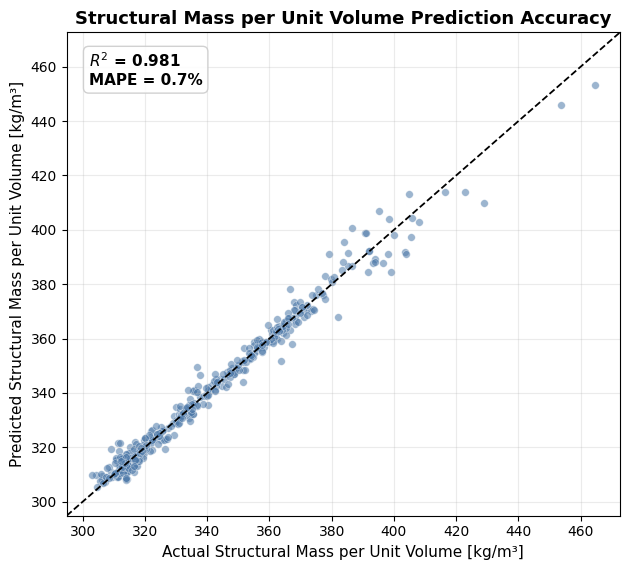

In [7]:
# ---------------------------------------------------
# INTERNAL VALIDATION FIGURE
# STRUCTURAL MASS PER UNIT VOLUME
# ---------------------------------------------------

# Create per-unit-volume columns for this figure
section6_internal_results["Actual Structural Mass per Unit Volume"] = (
    section6_internal_results["Actual Structural Mass"]
    / section6_internal_results["Actual Metric Volume"]
)

section6_internal_results["Predicted Structural Mass per Unit Volume"] = (
    section6_internal_results["Predicted Structural Mass"]
    / section6_internal_results["Actual Metric Volume"]
)

# Accuracy metrics for structural mass per unit volume
mass_per_volume_r2 = r2_score(
    section6_internal_results["Actual Structural Mass per Unit Volume"],
    section6_internal_results["Predicted Structural Mass per Unit Volume"]
)

mass_per_volume_mape = np.abs(
    100
    * (
        section6_internal_results["Predicted Structural Mass per Unit Volume"]
        - section6_internal_results["Actual Structural Mass per Unit Volume"]
    )
    / section6_internal_results["Actual Structural Mass per Unit Volume"]
).mean()

# Plot
fig, ax = plt.subplots(figsize=(6.4, 5.8))

ax.scatter(
    section6_internal_results["Actual Structural Mass per Unit Volume"],
    section6_internal_results["Predicted Structural Mass per Unit Volume"],
    s=30,
    color="#4C78A8",
    alpha=0.55,
    edgecolors="white",
    linewidths=0.4
)

min_value, max_value = section6_reference_limits(
    section6_internal_results["Actual Structural Mass per Unit Volume"],
    section6_internal_results["Predicted Structural Mass per Unit Volume"]
)

ax.plot(
    [min_value, max_value],
    [min_value, max_value],
    "k--",
    linewidth=1.3
)

ax.set_xlim(min_value, max_value)
ax.set_ylim(min_value, max_value)

ax.text(
    0.04,
    0.96,
    f"$R^2$ = {mass_per_volume_r2:.3f}\nMAPE = {mass_per_volume_mape:.1f}%",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=11,
    fontweight="bold",
    bbox=dict(
        facecolor="white",
        edgecolor="#cccccc",
        boxstyle="round,pad=0.35",
        alpha=0.9
    )
)

ax.set_title(
    "Structural Mass per Unit Volume Prediction Accuracy",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel(
    "Actual Structural Mass per Unit Volume [kg/m³]",
    fontsize=11
)

ax.set_ylabel(
    "Predicted Structural Mass per Unit Volume [kg/m³]",
    fontsize=11
)

ax.grid(True, alpha=0.25)

fig.tight_layout()
plt.show()

### Combined internal and external SOM validation figure

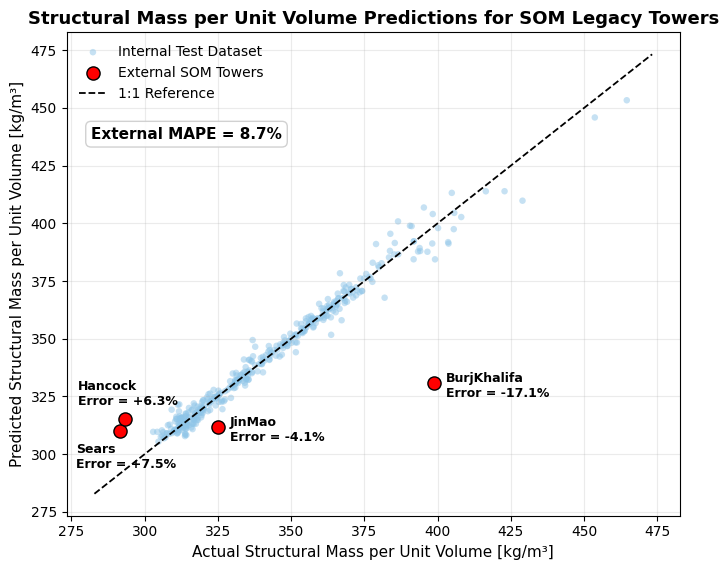

In [8]:
# ---------------------------------------------------
# SECTION 6
# COMBINED VALIDATION FIGURE - STRUCTURAL MASS PER UNIT VOLUME
# ---------------------------------------------------

# Add actual structural mass per unit volume for external towers
section6_external_results["Actual Structural Mass per Unit Volume"] = (
    section6_external_results["Actual Structural Mass"]
    / section6_external_results["Metric Volume"]
)

section6_external_results["Predicted Structural Mass per Unit Volume"] = (
    section6_external_results["Predicted Structural Mass Intensity"]
)

section6_external_results["Error"] = (
    section6_external_results["Predicted Structural Mass per Unit Volume"]
    - section6_external_results["Actual Structural Mass per Unit Volume"]
)

section6_external_results["Percent Error (%)"] = (
    100
    * section6_external_results["Error"]
    / section6_external_results["Actual Structural Mass per Unit Volume"]
)

# Internal results
section6_internal_combined_results = pd.DataFrame({
    "Source": "Internal",
    "Building ID": "",
    "Actual Structural Mass per Unit Volume":
        section6_internal_results["Actual Structural Mass Intensity"].to_numpy(dtype=float),
    "Predicted Structural Mass per Unit Volume":
        section6_internal_results["Predicted Structural Mass Intensity"].to_numpy(dtype=float)
})

# External results
section6_external_combined_results = pd.DataFrame({
    "Source": "External",
    "Building ID": section6_external_results["Building ID"].to_numpy(),
    "Actual Structural Mass per Unit Volume":
        section6_external_results["Actual Structural Mass per Unit Volume"].to_numpy(dtype=float),
    "Predicted Structural Mass per Unit Volume":
        section6_external_results["Predicted Structural Mass per Unit Volume"].to_numpy(dtype=float)
})

section6_combined_results = pd.concat(
    [
        section6_internal_combined_results,
        section6_external_combined_results
    ],
    ignore_index=True
)

section6_internal_plot = section6_combined_results[
    section6_combined_results["Source"] == "Internal"
]

section6_external_plot = section6_combined_results[
    section6_combined_results["Source"] == "External"
]

# ---------------------------------------------------
# Plot
# ---------------------------------------------------

fig, ax = plt.subplots(figsize=(7.0, 5.8))

ax.scatter(
    section6_internal_plot["Actual Structural Mass per Unit Volume"],
    section6_internal_plot["Predicted Structural Mass per Unit Volume"],
    s=22,
    alpha=0.5,
    color="#8EC5E8",
    edgecolor="none",
    label="Internal Test Dataset"
)

ax.scatter(
    section6_external_plot["Actual Structural Mass per Unit Volume"],
    section6_external_plot["Predicted Structural Mass per Unit Volume"],
    s=90,
    color="red",
    edgecolor="black",
    linewidth=1.0,
    zorder=10,
    label="External SOM Towers"
)

label_offsets = {
    "Hancock": (-30, 19),
    "JinMao": (9, -10),
    "BurjKhalifa": (9, -10),
    "Sears": (-35, -35)
}

error_lookup = (
    section6_external_results
    .set_index("Building ID")["Percent Error (%)"]
    .to_dict()
)

for _, row in section6_external_plot.iterrows():

    building = row["Building ID"]
    offset = label_offsets.get(building, (8, 6))
    error = error_lookup.get(building, np.nan)

    ax.annotate(
        f"{building}\nError = {error:+.1f}%",
        (
            row["Actual Structural Mass per Unit Volume"],
            row["Predicted Structural Mass per Unit Volume"]
        ),
        xytext=offset,
        textcoords="offset points",
        fontsize=9,
        fontweight="bold"
    )

external_mape = np.abs(
    section6_external_results["Percent Error (%)"]
).mean()

ax.text(
    0.04,
    0.78,
    f"External MAPE = {external_mape:.1f}%",
    transform=ax.transAxes,
    fontsize=11,
    fontweight="bold",
    bbox=dict(
        facecolor="white",
        edgecolor="#cccccc",
        boxstyle="round,pad=0.35",
        alpha=0.9
    )
)

min_value, max_value = section6_reference_limits(
    section6_combined_results["Actual Structural Mass per Unit Volume"],
    section6_combined_results["Predicted Structural Mass per Unit Volume"]
)

ax.plot(
    [min_value, max_value],
    [min_value, max_value],
    "k--",
    linewidth=1.3,
    label="1:1 Reference"
)

ax.set_title(
    "Structural Mass per Unit Volume Predictions for SOM Legacy Towers",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel(
    "Actual Structural Mass per Unit Volume [kg/m³]",
    fontsize=11
)

ax.set_ylabel(
    "Predicted Structural Mass per Unit Volume [kg/m³]",
    fontsize=11
)

ax.grid(True, alpha=0.25)
ax.legend(frameon=False, loc="upper left")

fig.tight_layout()
plt.show()

## Final validation tables

These tables display existing predictions; they do not refit or modify the model. Percent error is signed; MAPE is its mean absolute value.

In [9]:
def section6_display_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    return {
        "R²": r2_score(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE (%)": np.abs(100 * (predicted - actual) / actual).mean(),
    }

section6_final_external_table = pd.DataFrame({
    "Building ID": section6_external_results["Building ID"],
    "Actual Mass / Volume": section6_external_results["Actual Structural Mass"] / section6_external_results["Metric Volume"],
    "Predicted Mass / Volume": section6_external_results["Predicted Structural Mass Intensity"],
    "Actual Structural Mass": section6_external_results["Actual Structural Mass"],
    "Predicted Structural Mass": section6_external_results["Predicted Structural Mass"],
})
section6_final_external_table["Percent Error (%)"] = (
    100 * (section6_final_external_table["Predicted Structural Mass"] - section6_final_external_table["Actual Structural Mass"])
    / section6_final_external_table["Actual Structural Mass"]
)
section6_final_external_table = section6_final_external_table.set_index("Building ID").loc[section6_som_building_order].reset_index()
display(pd.DataFrame([
    {"Validation": "Internal Mass / Volume", **section6_display_metrics(section6_internal_actual_intensity, section6_internal_predicted_intensity)},
    {"Validation": "Internal Structural Mass", **section6_display_metrics(section6_internal_actual_mass, section6_internal_predicted_mass)},
    {"Validation": "External SOM Mass / Volume", **section6_display_metrics(section6_final_external_table["Actual Mass / Volume"], section6_final_external_table["Predicted Mass / Volume"])},
    {"Validation": "External SOM Structural Mass", **section6_display_metrics(section6_final_external_table["Actual Structural Mass"], section6_final_external_table["Predicted Structural Mass"])},
]))
display(section6_final_external_table)
print("Overall external SOM MAPE (%):", section6_final_external_table["Percent Error (%)"].abs().mean())
display(pd.DataFrame({
    "Feature": section6_feature_columns,
    "Importance": section6_model.feature_importances_,
}))

,Validation,R²,MAE,RMSE,MAPE (%)
0,Internal Mass / Volume,0.980731,2.557636e+00,3.814557e+00,0.734331
1,Internal Structural Mass,0.980731,7.596178e+05,1.132923e+06,0.734331
2,External SOM Mass / Volume,0.254281,3.043171e+01,3.750103e+01,8.742667
3,External SOM Structural Mass,0.775336,2.954653e+07,3.494618e+07,8.742667


,Building ID,Actual Mass / Volume,Predicted Mass / Volume,Actual Structural Mass,Predicted Structural Mass,Percent Error (%)
0,Hancock,291.507616,310.004734,261250000.0,2.778272e+08,6.345329
1,JinMao,324.910811,311.651953,253550000.0,2.432032e+08,-4.080769
2,BurjKhalifa,398.722992,330.715939,343830000.0,2.851856e+08,-17.056215
3,Sears,293.306434,315.270256,435580000.0,4.681978e+08,7.488353


Overall external SOM MAPE (%): 8.742666587609254


,Feature,Importance
0,Height,0.029811
1,Slenderness Ratio,0.845767
2,Plan Aspect Ratio,0.006283
3,Mean Compactness,0.015267
4,Plan Aspect Ratio Variation,0.014458
5,Max CoM,0.007158
6,Bulge Factor,0.000000
7,Bulge Height Index,0.000000
8,Top-to-Base Width Ratio,0.001967
9,Max-to-Min Width Ratio,0.001830


## Save the existing trained thesis model

Run **only the following cell** in the kernel that already holds the verified
`section6_model`. It serializes that exact fitted object and does not train,
refit, change features, or change preprocessing. If the trained state is absent,
it stops with an explanatory error.

The separate filename is `structural_mass_model_thesis.joblib`; the existing
`structural_mass_model.joblib` is protected by a before/after file hash check.
Reload checks use zero-tolerance numerical equality. The standalone script is
`predict_structural_mass_thesis.py` beside this notebook; supply already-cleaned
metrics by their exact saved names. No metric transformations are applied by it.

In [10]:
# SAVE AND VERIFY THE EXISTING TRAINED SECTION 6 MODEL ONLY
from pathlib import Path
import hashlib
import json
import joblib
import numpy as np
import sklearn
from sklearn.utils.validation import check_is_fitted

_thesis_required = [
    "section6_model", "section6_feature_columns", "section6_X_train",
    "section6_training_df", "section6_X_test",
]
_thesis_missing = [name for name in _thesis_required if name not in globals()]
if _thesis_missing:
    raise RuntimeError(
        "The existing trained Section 6 state is not available in this kernel: "
        + ", ".join(_thesis_missing)
        + ". Select the kernel containing that trained model. This cell does not train or recreate it."
    )
check_is_fitted(section6_model)
assert list(section6_model.feature_names_in_) == list(section6_feature_columns)
assert list(section6_X_test.columns) == list(section6_feature_columns)
_thesis_original_model_hash = joblib.hash(section6_model)

thesis_results_folder = Path(
    r"C:\Users\lilli\OneDrive\Desktop\Master Thesis\Grasshopper Data\MidJune\PredictionModelResults"
)
thesis_model_output_path = thesis_results_folder / "structural_mass_model_thesis.joblib"
_thesis_protected_path = thesis_results_folder / "structural_mass_model.joblib"
assert thesis_model_output_path.resolve() != _thesis_protected_path.resolve()
_thesis_protected_hash = (
    hashlib.sha256(_thesis_protected_path.read_bytes()).hexdigest()
    if _thesis_protected_path.exists() else None
)

thesis_model_package = {
    "model": section6_model,
    "feature_columns": section6_feature_columns.copy(),
    "target": "Mass / Volume",
    "target_definition": "Structural Mass / Metric Volume",
    "target_units": "kg/m³",
    "model_type": "RandomForestRegressor",
    "sklearn_version": sklearn.__version__,
    "model_settings": section6_model.get_params(),
    "n_features": len(section6_feature_columns),
    "training_rows": len(section6_X_train),
    "eligible_rows": len(section6_training_df),
    "test_rows": len(section6_X_test),
    "input_convention": (
        "Supply the already-prepared geometry metrics in the notebook's conventions, "
        "including reciprocal Plan Aspect Ratio. The estimator contains no preprocessing "
        "or missing-value filling. Feature order is defined by feature_columns."
    ),
}
thesis_model_output_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(thesis_model_package, thesis_model_output_path, compress=3)

thesis_loaded_package = joblib.load(thesis_model_output_path)
thesis_loaded_model = thesis_loaded_package["model"]
thesis_features_identical = thesis_loaded_package["feature_columns"] == section6_feature_columns
thesis_parameters_identical = thesis_loaded_model.get_params() == section6_model.get_params()
assert thesis_features_identical
assert thesis_parameters_identical
assert thesis_loaded_package["model_settings"] == section6_model.get_params()

_thesis_internal_original = section6_model.predict(section6_X_test)
_thesis_internal_loaded = thesis_loaded_model.predict(section6_X_test)
thesis_internal_identical = bool(np.allclose(
    _thesis_internal_original, _thesis_internal_loaded, rtol=0, atol=0,
))
assert thesis_internal_identical

thesis_external_identical = None
if "section6_external_X" in globals():
    assert list(section6_external_X.columns) == section6_feature_columns
    thesis_external_identical = bool(np.allclose(
        section6_model.predict(section6_external_X),
        thesis_loaded_model.predict(section6_external_X),
        rtol=0, atol=0,
    ))
    assert thesis_external_identical

thesis_importances_identical = bool(np.allclose(
    section6_model.feature_importances_, thesis_loaded_model.feature_importances_,
    rtol=0, atol=0,
))
assert thesis_importances_identical
assert joblib.hash(section6_model) == _thesis_original_model_hash
if _thesis_protected_hash is not None:
    assert hashlib.sha256(_thesis_protected_path.read_bytes()).hexdigest() == _thesis_protected_hash

thesis_verification = {
    "model_path": str(thesis_model_output_path.resolve()),
    "feature_columns": thesis_loaded_package["feature_columns"],
    "model_settings": thesis_loaded_model.get_params(),
    "feature_list_identical": thesis_features_identical,
    "model_parameters_identical": thesis_parameters_identical,
    "internal_predictions_identical": thesis_internal_identical,
    "external_som_predictions_identical": thesis_external_identical,
    "feature_importances_identical": thesis_importances_identical,
    "existing_model_unchanged": True,
    "protected_file_sha256": _thesis_protected_hash,
}
thesis_model_output_path.with_suffix(".verification.json").write_text(
    json.dumps(thesis_verification, indent=2, ensure_ascii=False), encoding="utf-8",
)
print(f"Model saved: {thesis_model_output_path.resolve()}")
print(f"Feature list identical: {thesis_features_identical}")
print(f"Model parameters identical: {thesis_parameters_identical}")
print(f"Internal predictions identical: {thesis_internal_identical}")
print("External SOM predictions identical:", thesis_external_identical if thesis_external_identical is not None else "not checked (input dataframe unavailable)")
print(f"Feature importances identical: {thesis_importances_identical}")
print("Existing in-memory model unchanged: True")
print("Existing structural_mass_model.joblib unchanged:", True if _thesis_protected_hash is not None else "not present")
print("Saved feature order:", thesis_loaded_package["feature_columns"])
print("Saved Random Forest settings:", thesis_loaded_package["model_settings"])


Model saved: C:\Users\lilli\OneDrive\Desktop\Master Thesis\Grasshopper Data\MidJune\PredictionModelResults\structural_mass_model_thesis.joblib
Feature list identical: True
Model parameters identical: True
Internal predictions identical: True
External SOM predictions identical: True
Feature importances identical: True
Existing in-memory model unchanged: True
Existing structural_mass_model.joblib unchanged: True
Saved feature order: ['Height', 'Slenderness Ratio', 'Plan Aspect Ratio', 'Mean Compactness', 'Plan Aspect Ratio Variation', 'Max CoM', 'Bulge Factor', 'Bulge Height Index', 'Top-to-Base Width Ratio', 'Max-to-Min Width Ratio', 'Mean Floor Area Decrease (%)', 'Mean Floor Area Increase (%)', 'Number of Setbacks', 'Mean Setback Magnitude', 'Weighted Mean Setback Height', 'Mean Inward Taper (%)', 'Mean Outward Taper (%)', 'Taper Sign Change', 'Facade Verticality Ratio']
Saved Random Forest settings: {'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None